# Timeseries correlation

One of ways of comparing timeseries between themselves, can be explored with help of timeseries to graph conversion techniques:

## Comparing whole segment

Firstly we can convert timeseries into a single node, and connect different nodes, each representing their own series, with edge weight being equal to the correlation between two timeseries. Here we will demonstrate using Person correlation technique.

In [2]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")

import warnings
warnings.filterwarnings('ignore')

import utils
from visualization import draw_g

from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.view import get_view_strategy
from strategies.merge import get_link_multigraph_strategy_builder
from pipeline import T2G2Pipeline
from strategies.merge.strategy_linking_multigraph import PearsonCorrelation
amazon_path = os.path.join(os.getcwd(), "amazon", "AMZN.csv")


Applying viewing strategy: <strategies.view.views.SliceView object at 0x7fe72a9500e0>
Number of dimensions: 1; total windows: 1


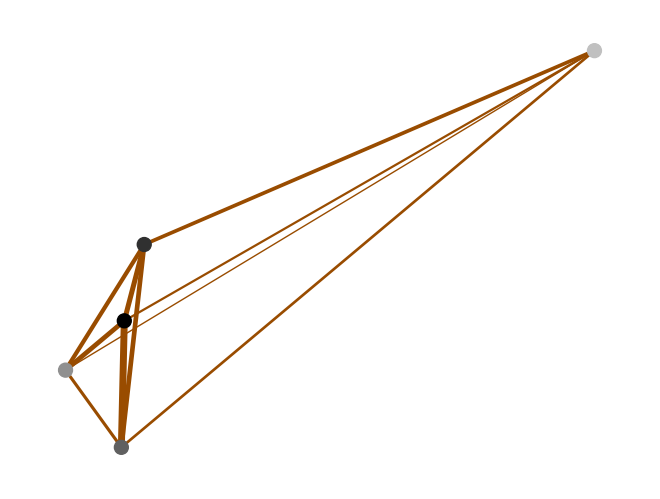

In [3]:

ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

views = [
    get_view_strategy("slice")(start_index=60, end_index=90),
    get_view_strategy("slice")(start_index=120, end_index=150),
    get_view_strategy("slice")(start_index=180, end_index=210),
    get_view_strategy("slice")(start_index=240, end_index=270),
    get_view_strategy("slice")(start_index=300, end_index=330),
]

ts2g_builder = get_ts2g_strategy_builder(method="pearson")
ts2g_strategy = ts2g_builder().get_strategy()

merge_builder = get_link_multigraph_strategy_builder()
link_strategy = merge_builder().correlation(PearsonCorrelation())

pipeline = T2G2Pipeline().load_timeseries(ts_data)
for i, v in enumerate(views):
    if i == 0:
        pipeline = pipeline.viewing(v)
    else:
        pipeline = pipeline.add_view(v)

(
    pipeline.to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
)

G = pipeline.get_Graph()
draw_g(G)

## Comparing segments using sliding window mechanism

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7fe87074a6c0>
Number of dimensions: 1; total windows: 1
Applying viewing strategy: <strategies.view.views.FixedOverlapWindow object at 0x7fe72a56d7f0>
Number of dimensions: 1; total windows: 16


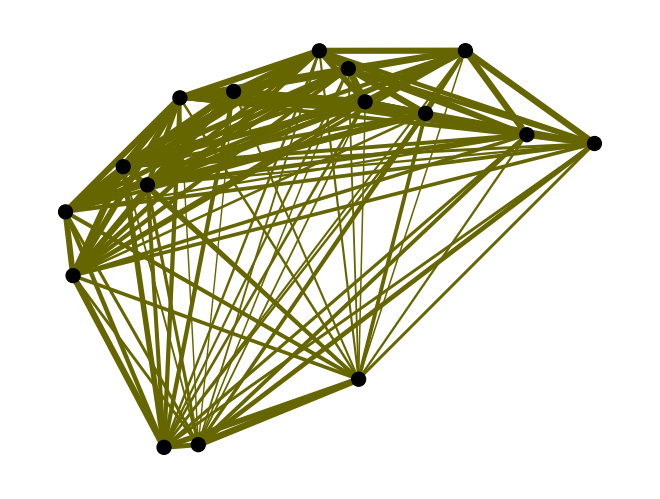

In [4]:

ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# viewing: segmentation(60,80) -> sliding window(window=5, step=1)
view_seg = get_view_strategy("slice")(start_index=60, end_index=80)
view_sw  = get_view_strategy("sliding_window")(window_size=5, step_size=1)

# TS->Graph: Pearson correlation
ts2g_builder  = get_ts2g_strategy_builder(method="pearson")
ts2g_strategy = ts2g_builder().get_strategy()

# Link across windows: correlation_sliding_window
merge_builder = get_link_multigraph_strategy_builder()
link_strategy = merge_builder().correlation_sliding_window(PearsonCorrelation())

# pipeline
pipeline = T2G2Pipeline()
(
    pipeline.load_timeseries(ts_data)
            .viewing(view_seg)
            .viewing(view_sw)
            .to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
)

# draw
G = pipeline.get_Graph()
draw_g(G)

we can use same mechanism on multiple different timeseries and compare equally positioned windows of data:

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7fe729493ec0>
Number of dimensions: 1; total windows: 1
Applying viewing strategy: <strategies.view.views.FixedOverlapWindow object at 0x7fe72b11e3c0>
Number of dimensions: 2; total windows: 12


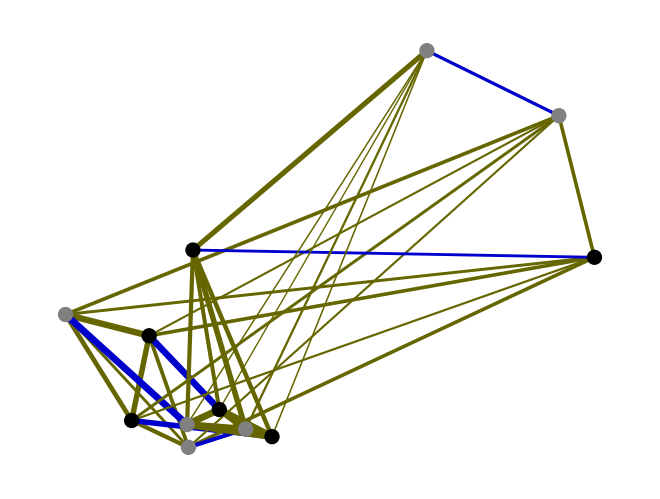

In [5]:

ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# view1: slice(60,70) -> sliding window(5)
v1_seg = get_view_strategy("slice")(start_index=60, end_index=70)
v2_seg = get_view_strategy("slice")(start_index=120, end_index=130)
v3_sw  = get_view_strategy("sliding_window")(window_size=5, step_size=1)


# ts->graph: Pearson correlation
ts2g_builder  = get_ts2g_strategy_builder(method="pearson")
ts2g_strategy = ts2g_builder().get_strategy()

# link across graphs: correlation_sliding_window + positional_correlation_sliding_window
merge_builder = get_link_multigraph_strategy_builder()
link_strategy = (
    merge_builder()
        .correlation_sliding_window(PearsonCorrelation())
        .positional_correlation_sliding_window(PearsonCorrelation())
)

# pipeline
pipeline = T2G2Pipeline()
(
    pipeline.load_timeseries(ts_data)
            .viewing(v1_seg)
            .add_view(v2_seg)
            .viewing(v3_sw)
            .to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
)

# draw
G = pipeline.get_Graph()
draw_g(G)

## Connecting multivariate visibility graph based on dynamic time warping

We also provide method that, connects multiple visibility graphs into one multivariate one based on dynamic time warping. Speciality of this method is, that you do not need to provide graphs / timeseries of the same length for it to work.

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7fe870749130>
Number of dimensions: 1; total windows: 1


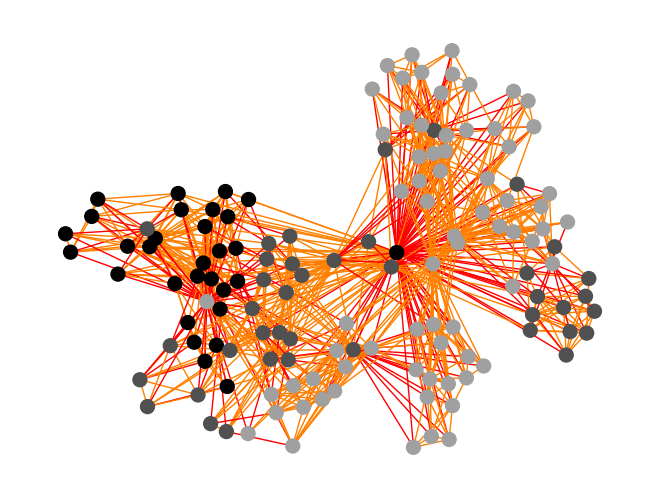

In [6]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")

import warnings
warnings.filterwarnings("ignore")

import utils
from visualization import draw_g

from pipeline import T2G2Pipeline
from strategies.view import get_view_strategy
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.merge import get_link_multigraph_strategy_builder

# data
amazon_path = os.path.join(os.getcwd(), "amazon", "AMZN.csv")
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# three slice views: [60,90), [90,130), [130,200)
v1 = get_view_strategy("slice")(start_index=60,  end_index=90)
v2 = get_view_strategy("slice")(start_index=90,  end_index=130)
v3 = get_view_strategy("slice")(start_index=130, end_index=200)

# ts->graph: Natural Visibility with limit(1)
ts2g_builder  = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().with_limit(1).get_strategy()

# multi-graph linking: Dynamic Time Warping
merge_builder = get_link_multigraph_strategy_builder()
link_strategy = merge_builder().dynamic_timewarping()

# pipeline
pipeline = T2G2Pipeline()
(
    pipeline.load_timeseries(ts_data)
            .viewing(v1)
            .add_view(v2)
            .add_view(v3)
            .to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
)

# draw
G = pipeline.get_Graph()
draw_g(G)